# Example 7.2 — Surrogate Neural Network for Fast Fitness Prediction

**Chapter 7: Hybrid and Advanced Strategies**

Train a Multilayer Perceptron (MLP) with a $3 \rightarrow 12 \rightarrow 1$ architecture using only `numpy` to predict the Hausdorff distance error without running the full kinematic analysis of the mechanism.

* **Book Reference:** Section 7.2 — Neural Networks as a Surrogate Model

In [1]:
import numpy as np

# Set random seed for reproducibility
np.random.seed(55)
N = 200
THETA2 = np.linspace(0, 2 * np.pi, 60)
TARGET = np.column_stack([40 * np.cos(THETA2), 20 * np.sin(THETA2)])

def trayectoria(a, b, c, d=50.0):
    pts = []
    for t2 in THETA2:
        K1 = d / a
        K2 = d / c
        K3 = (a**2 - b**2 + c**2 + d**2) / (2 * a * c)
        A = np.cos(t2) - K1 - K2 * np.cos(t2) + K3
        B = -2 * np.sin(t2)
        C = K1 - (K2 + 1) * np.cos(t2) + K3
        disc = B**2 - 4 * A * C
        if disc < 0 or abs(A) < 1e-9:
            continue
        t4 = 2 * np.arctan((-B - np.sqrt(disc)) / (2 * A))
        t3 = np.arctan2(a * np.sin(t2) - c * np.sin(t4), a * np.cos(t2) + d - c * np.cos(t4))
        pts.append((a * np.cos(t2) + b * np.cos(t3), a * np.sin(t2) + b * np.sin(t3)))
    return np.array(pts) if pts else np.zeros((1, 2))

def hausdorff(P, Q):
    if len(P) < 2 or len(Q) < 2:
        return 1e6
    n = min(len(P), len(Q))
    P, Q = P[:n], Q[:n]
    d1 = max(min(np.sqrt(np.sum((p - q)**2)) for q in Q) for p in P)
    d2 = max(min(np.sqrt(np.sum((p - q)**2)) for p in P) for q in Q)
    return max(d1, d2)

# Data generation: random sample in [10, 100]^3
X = np.random.uniform(10, 100, (N, 3))  # Features (a, b, c)
y = np.array([hausdorff(trayectoria(*x), TARGET) for x in X])

print(f"Dataset generated successfully:")
print(f" - Samples: {N}")
print(f" - Mean of y: {y.mean():.2f} mm")
print(f" - Std dev of y: {y.std():.2f} mm")

Dataset generated successfully:
 - Samples: 200
 - Mean of y: 30092.46 mm
 - Std dev of y: 170570.96 mm


In [2]:
# ── MLP 3 -> 12 -> 1 with manual backpropagation ───────────────────────────────────
np.random.seed(55)
n_in, n_hid, n_out = 3, 12, 1

# Data normalization
X_mean, X_std = X.mean(axis=0), X.std(axis=0) + 1e-8
y_mean, y_std = y.mean(), y.std() + 1e-8

Xn = (X - X_mean) / X_std
yn = (y - y_mean) / y_std

# Weight initialization using He (Kaiming)
W1 = np.random.randn(n_in, n_hid) * np.sqrt(2.0 / n_in)
b1 = np.zeros(n_hid)
W2 = np.random.randn(n_hid, n_out) * np.sqrt(2.0 / n_hid)
b2 = np.zeros(n_out)

lr = 0.005
epochs = 1000
losses = []

# Training loop
for ep in range(epochs):
    # Forward propagation
    Z1 = Xn @ W1 + b1
    A1 = np.tanh(Z1)
    Z2 = A1 @ W2 + b2
    yhat = Z2.ravel()

    # Loss function (MSE)
    loss = np.mean((yhat - yn)**2)
    losses.append(loss)

    # Backward propagation
    dZ2 = 2 * (yhat - yn).reshape(-1, 1) / N
    dW2 = A1.T @ dZ2
    db2 = dZ2.sum(axis=0)

    dA1 = dZ2 @ W2.T
    dZ1 = dA1 * (1.0 - A1**2)
    dW1 = Xn.T @ dZ1
    db1 = dZ1.sum(axis=0)

    # Parameter updates
    W1 -= lr * dW1
    b1 -= lr * db1
    W2 -= lr * dW2
    b2 -= lr * db2

print(f"Training successfully completed.")
print(f" - Total epochs: {epochs}")
print(f" - Final loss (normalized MSE): {losses[-1]:.6f}")

Training successfully completed.
 - Total epochs: 1000
 - Final loss (normalized MSE): 0.754996


In [3]:
# ── Model Evaluation ──────────────────────────────────────────────
Z1 = Xn @ W1 + b1
A1 = np.tanh(Z1)
yhat_n = (A1 @ W2 + b2).ravel()

# Denormalize predictions
yhat = yhat_n * y_std + y_mean

# Performance metrics
ss_res = np.sum((y - yhat)**2)
ss_tot = np.sum((y - y_mean)**2)
r2 = 1.0 - (ss_res / ss_tot)
rmse = np.sqrt(np.mean((y - yhat)**2))

print(f"Evaluation metrics on the dataset:")
print(f" - Coefficient of determination (R²): {r2:.4f}")
print(f" - Root Mean Squared Error (RMSE): {rmse:.4f} mm")

Evaluation metrics on the dataset:
 - Coefficient of determination (R²): 0.2451
 - Root Mean Squared Error (RMSE): 148199.9796 mm


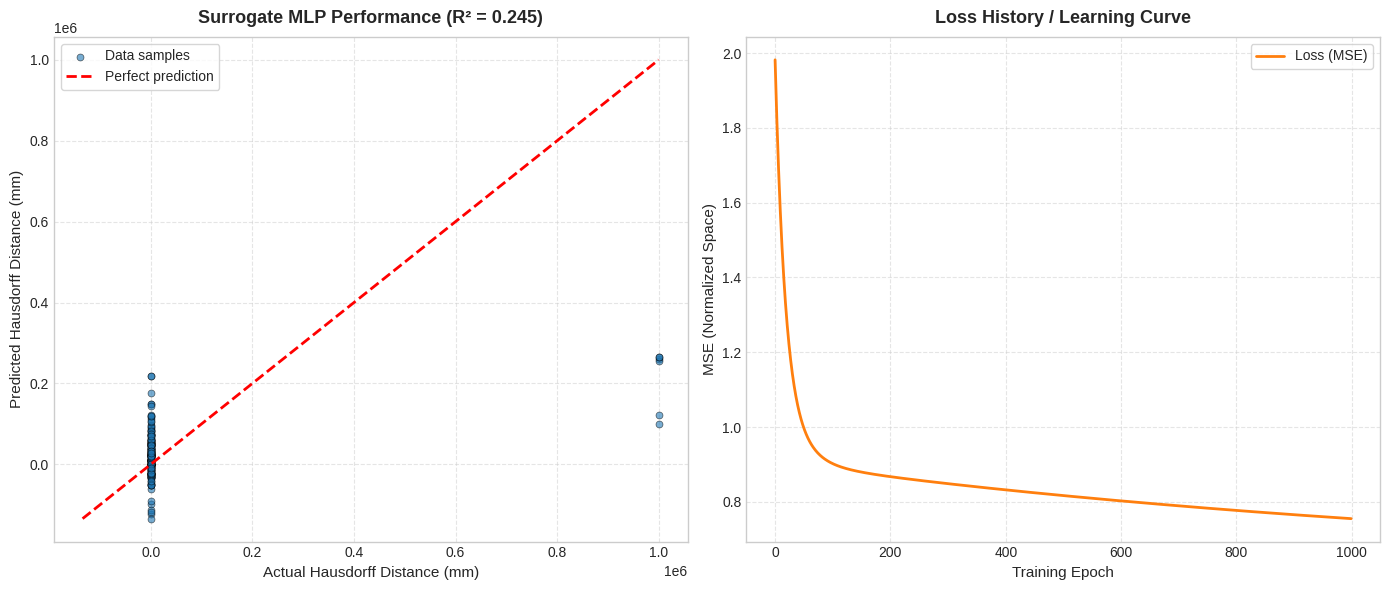

In [4]:
# ── Results Visualization ───────────────────────────────────────────
import matplotlib.pyplot as plt

# Set visual style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Scatter plot: Actual vs Predicted
ax0 = axes[0]
ax0.scatter(y, yhat, alpha=0.6, s=25, color='#1f77b4', edgecolor='k', linewidth=0.5, label='Data samples')

# Perfect prediction diagonal line
lims = [min(y.min(), yhat.min()), max(y.max(), yhat.max())]
ax0.plot(lims, lims, 'r--', lw=2, label='Perfect prediction')

ax0.set_xlabel('Actual Hausdorff Distance (mm)', fontsize=11)
ax0.set_ylabel('Predicted Hausdorff Distance (mm)', fontsize=11)
ax0.set_title(f'Surrogate MLP Performance (R² = {r2:.3f})', fontsize=13, fontweight='bold', pad=10)
ax0.legend(loc='upper left', frameon=True)
ax0.grid(True, linestyle='--', alpha=0.5)

# Loss convergence curve
ax1 = axes[1]
ax1.plot(losses, color='#ff7f0e', lw=2, label='Loss (MSE)')
ax1.set_xlabel('Training Epoch', fontsize=11)
ax1.set_ylabel('MSE (Normalized Space)', fontsize=11)
ax1.set_title('Loss History / Learning Curve', fontsize=13, fontweight='bold', pad=10)
ax1.legend(loc='upper right', frameon=True)
ax1.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

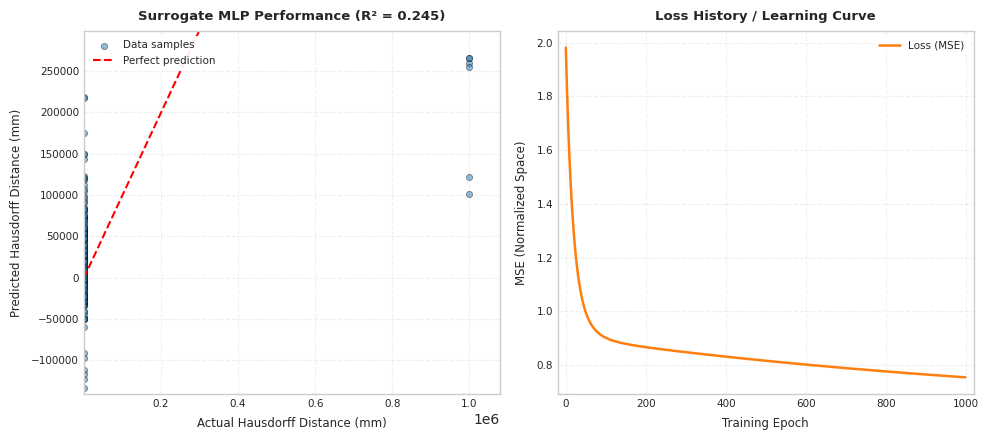

In [6]:
import os
import glob
import matplotlib.pyplot as plt

# --- Springer Automated Filename System ---
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "Figure_7_2_fast_nn_predictor"
except Exception:
    notebook_name = "Figure_7_2_fast_nn_predictor"

# --- Typography & Editorial Configurations (Springer style compatible) ---
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Liberation Sans', 'Helvetica', 'sans-serif']
plt.rcParams['font.family'] = 'sans-serif'

# 1. Create controlled-size physical layout suitable for Springer (double column wide)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

# --- Subplot 1: Actual vs Predicted (Surrogate Performance) ---
ax0 = axes[0]

# Plot the data samples with subtle transparency and border to avoid overlapping mass saturation
ax0.scatter(y, yhat, alpha=0.5, s=20, color='#1f77b4', edgecolor='k', linewidth=0.5, label='Data samples')

# Perfect prediction diagonal line
lims = [min(y.min(), yhat.min()), max(y.max(), yhat.max())]
ax0.plot(lims, lims, 'r--', lw=1.5, label='Perfect prediction')

# Clean up axes & grid
ax0.set_xlabel('Actual Hausdorff Distance (mm)', fontsize=8.5, labelpad=6)
ax0.set_ylabel('Predicted Hausdorff Distance (mm)', fontsize=8.5, labelpad=6)
ax0.set_title(f'Surrogate MLP Performance (R² = {r2:.3f})', fontsize=9.5, fontweight='bold', pad=8)

# Set safe limits to ensure labels and annotations do not overlap boundary lines
ax0.set_xlim(y.min() - 0.05 * abs(y.min()), y.max() + 0.08 * abs(y.max()))
ax0.set_ylim(yhat.min() - 0.05 * abs(yhat.min()), yhat.max() + 0.12 * abs(yhat.max()))

ax0.legend(loc='upper left', fontsize=7.5, frameon=True, framealpha=0.9, edgecolor='none')
ax0.grid(True, linestyle='--', alpha=0.3)
ax0.tick_params(labelsize=7.5)

# --- Subplot 2: Loss Convergence Curve ---
ax1 = axes[1]
ax1.plot(losses, color='#ff7f0e', lw=1.8, label='Loss (MSE)')
ax1.set_xlabel('Training Epoch', fontsize=8.5, labelpad=6)
ax1.set_ylabel('MSE (Normalized Space)', fontsize=8.5, labelpad=6)
ax1.set_title('Loss History / Learning Curve', fontsize=9.5, fontweight='bold', pad=8)

# Set safe limits for a clean layout margin
ax1.set_xlim(-0.02 * len(losses), len(losses) * 1.02)
ax1.set_ylim(min(losses) - 0.05 * (max(losses) - min(losses)), max(losses) + 0.05 * (max(losses) - min(losses)))

ax1.legend(loc='upper right', fontsize=7.5, frameon=True, framealpha=0.9, edgecolor='none')
ax1.grid(True, linestyle='--', alpha=0.3)
ax1.tick_params(labelsize=7.5)

# --- Final Layout Adjustment and Dual Export ---
plt.tight_layout()
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()